<a href="https://colab.research.google.com/github/cleanesantos/aulas-modelos-datascience/blob/main/Aula_Titanic_Regressao_Logistica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula prática: Titanic, análise exploratória e regressão logística

**Objetivo:** compreender o caminho completo de uma análise: aquisição, inspeção, visualização, preparação, treinamento e avaliação de um classificador.

**Ambiente:** Google Colab. **Dados:** conjunto público Titanic (891 registros da competição Kaggle, espelhado no repositório Data Science Dojo). **Não é necessário adicionar arquivos no Kaggle.**

**Orientação para a aula:** execute as células na ordem. Não execute somente o final: as variáveis são criadas ao longo do notebook. O conjunto usado neste material possui a coluna `Survived` e será dividido internamente em treino e teste.

## 1. Problema e objetivo de aprendizagem

O Titanic naufragou em 1912. Neste exercício, cada linha representa um passageiro do conjunto disponibilizado para treinamento na competição Titanic, e a coluna `Survived` indica 0 (não sobreviveu) ou 1 (sobreviveu).

**Pergunta:** com base nas características registradas dos passageiros, conseguimos construir um modelo para classificar a sobrevivência?

**Atenção:** este é um exercício didático com dados históricos observacionais. As associações encontradas não comprovam relações causais.

## 2. Importar bibliotecas e carregar os dados

`import` disponibiliza bibliotecas; `as` cria um apelido. `pd.read_csv()` lê uma tabela CSV e retorna um `DataFrame`. A variável `df_train` é mantida para acompanhar o material original, mas contém, neste momento, **todos os 891 registros disponíveis**.

In [29]:
import pandas as pd

# Endereço da base Titanic no GitHub
url = "https://raw.githubusercontent.com/cleanesantos/aulas-modelos-datascience/main/Titanic-Dataset.csv"

# Leitura correta do arquivo
df_train = pd.read_csv(
    url,
    sep=",",
    quotechar='"',
    encoding="utf-8-sig"
)

# Conferir dimensões
print("Dimensões:", df_train.shape)

# Visualizar os dados
display(df_train.head())

Dimensões: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 2.1. Vocabulário básico

`DataFrame`: tabela do pandas. `df_train`: nome da variável que guarda a tabela. `.head()`: mostra as primeiras linhas. `.shape`: atributo que devolve `(linhas, colunas)`. `.info()`: estrutura e tipos. `NaN`: valor ausente.

Principais variáveis: `Survived` (resultado), `Pclass` (classe), `Sex` (sexo registrado), `Age` (idade), `SibSp` (irmãos/cônjuges a bordo), `Parch` (pais/filhos a bordo), `Fare` (tarifa) e `Embarked` (porto de embarque).

In [30]:
print("Dimensões:", df_train.shape)
print("Colunas:", df_train.columns.tolist())
df_train.info()
display(df_train.describe(include="all").T)

Dimensões: (891, 12)
Colunas: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


## 3. Verificação da qualidade dos dados

Antes de calcular indicadores, investigamos ausências, duplicações e valores improváveis. `isna()` identifica valores ausentes; `.sum()` contabiliza valores verdadeiros em cada coluna. A ausência de dados não significa automaticamente que o registro deva ser excluído.

In [31]:
faltantes = pd.DataFrame({
    "ausentes": df_train.isna().sum(),
    "percentual": 100 * df_train.isna().mean()
}).sort_values("ausentes", ascending=False)
display(faltantes)
print("Linhas totalmente duplicadas:", df_train.duplicated().sum())
print("PassengerId duplicados:", df_train["PassengerId"].duplicated().sum())

,ausentes,percentual
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467
PassengerId,0,0.000000
Name,0,0.000000
Pclass,0,0.000000
Survived,0,0.000000
Sex,0,0.000000
Parch,0,0.000000
SibSp,0,0.000000


Linhas totalmente duplicadas: 0
PassengerId duplicados: 0


## 4. Análise exploratória

Os gráficos a seguir descrevem **este conjunto de passageiros**, não todos os ocupantes do navio. A média de uma variável binária 0/1 corresponde à proporção de valores 1.

Sobrevivência observada:


,count
Survived,
Não sobreviveu,549
Sobreviveu,342


Proporção observada de sobreviventes: 38.4%


/tmp/ipykernel_705/1153529801.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Não sobreviveu", "Sobreviveu"])


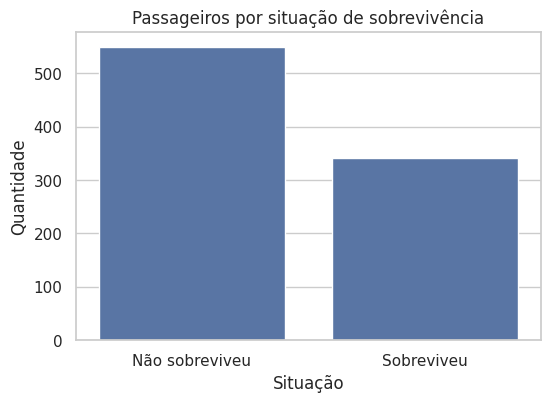

In [32]:
print("Sobrevivência observada:")
display(df_train["Survived"].value_counts().rename(index={0:"Não sobreviveu",1:"Sobreviveu"}))
print(f"Proporção observada de sobreviventes: {df_train['Survived'].mean():.1%}")
fig, ax = plt.subplots(figsize=(6,4))
sns.countplot(data=df_train, x="Survived", order=[0,1], ax=ax)
ax.set_xticklabels(["Não sobreviveu", "Sobreviveu"])
ax.set(xlabel="Situação", ylabel="Quantidade", title="Passageiros por situação de sobrevivência")
plt.show()

### 4.1. Comparar grupos

Nos gráficos abaixo, a altura da barra representa a **taxa observada de sobrevivência**, e não o número de passageiros. Não confunda proporção com quantidade.

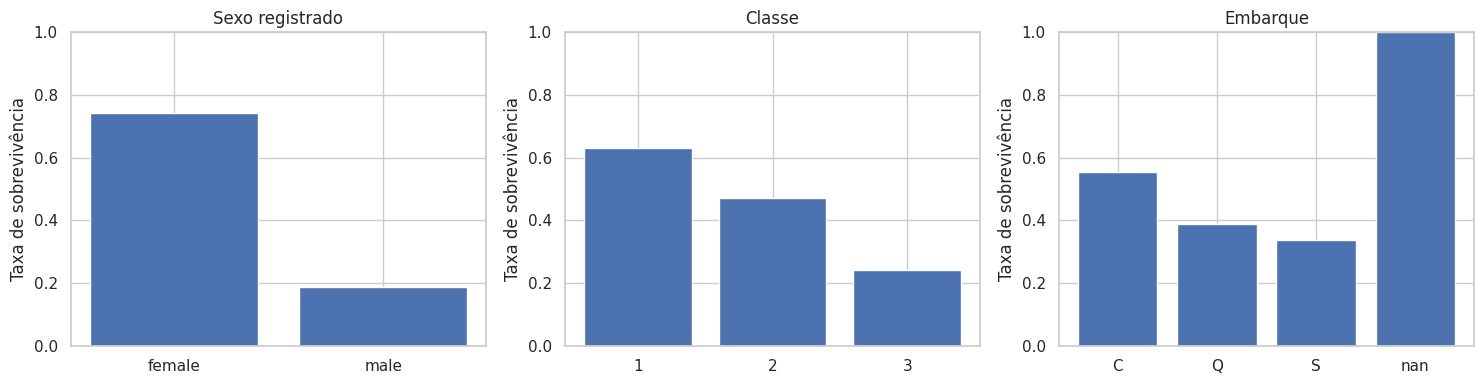

count      mean
Sex    Pclass                 
female 1          94  0.968085
       2          76  0.921053
       3         144  0.500000
male   1         122  0.368852
       2         108  0.157407
       3         347  0.135447

In [17]:
fig, eixos = plt.subplots(1,3,figsize=(15,4))
for ax, coluna, titulo in zip(eixos,["Sex","Pclass","Embarked"],["Sexo registrado","Classe","Embarque"]):
    taxas = df_train.groupby(coluna, dropna=False)["Survived"].mean()
    ax.bar(taxas.index.astype(str), taxas.values)
    ax.set_ylim(0,1)
    ax.set_title(titulo)
    ax.set_ylabel("Taxa de sobrevivência")
plt.tight_layout()
plt.show()
display(df_train.groupby(["Sex","Pclass"])["Survived"].agg(["count","mean"]))

### 4.2. Idade, tarifa e valores atípicos

Um *boxplot* resume mediana, quartis e possíveis valores atípicos segundo a regra de 1,5 vez a distância interquartílica. Um valor atípico **não é necessariamente um erro**.

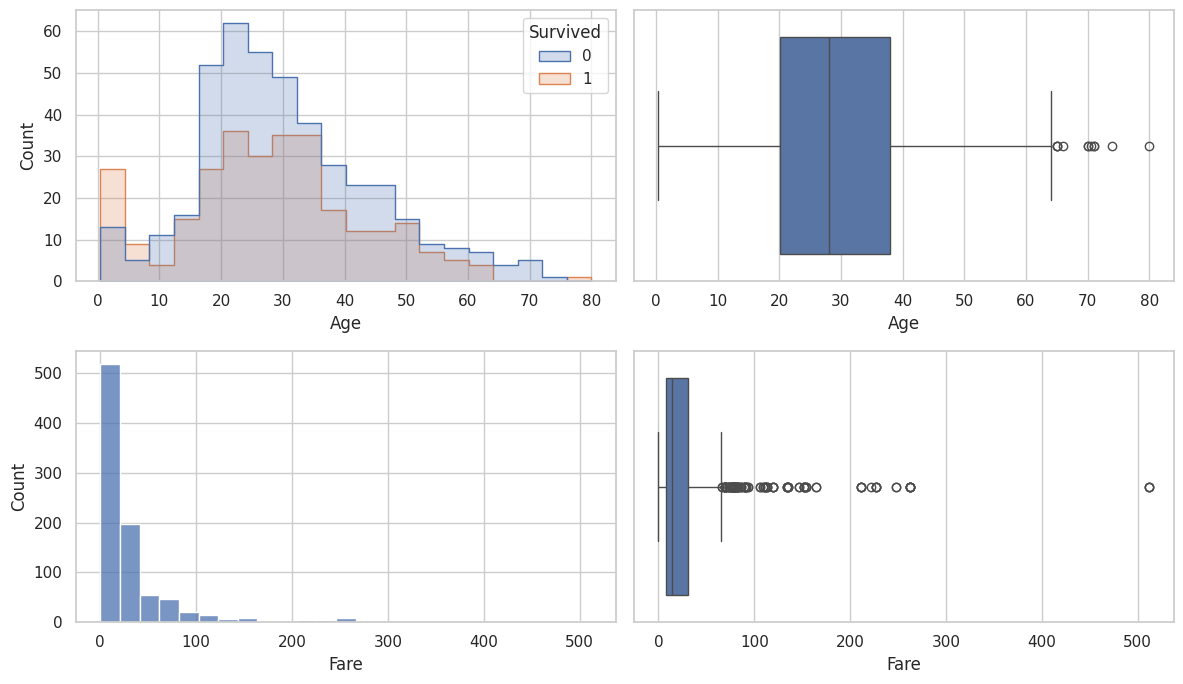

Quartis de idade:


,Age
0.25,20.125
0.50,28.000
0.75,38.000


In [18]:
fig, axes=plt.subplots(2,2,figsize=(12,7))
sns.histplot(data=df_train,x="Age",hue="Survived",bins=20,element="step",ax=axes[0,0])
sns.boxplot(data=df_train,x="Age",ax=axes[0,1])
sns.histplot(data=df_train,x="Fare",bins=25,ax=axes[1,0])
sns.boxplot(data=df_train,x="Fare",ax=axes[1,1])
plt.tight_layout(); plt.show()
print("Quartis de idade:")
display(df_train["Age"].quantile([.25,.5,.75]))

### 4.3. Correlações

A correlação de Pearson mede a associação linear entre variáveis numéricas. Ela não expressa causalidade. Variáveis nominais como `Sex` e `Embarked` não devem entrar diretamente numa matriz de correlação como se tivessem uma escala numérica natural.

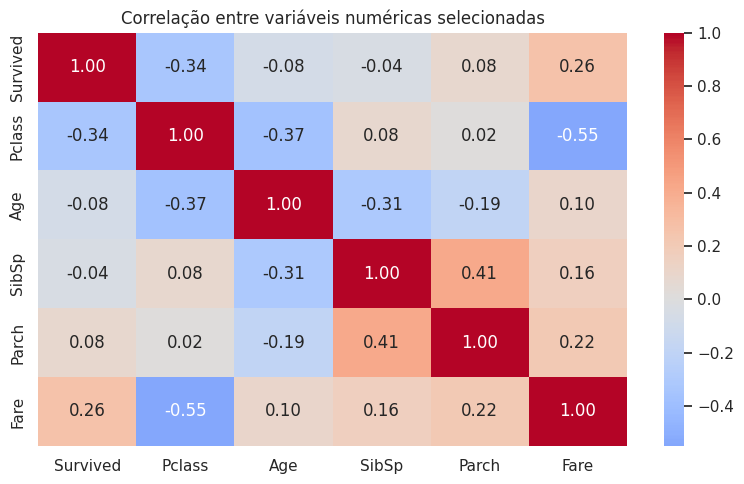

In [19]:
numericas = ["Survived","Pclass","Age","SibSp","Parch","Fare"]
plt.figure(figsize=(8,5))
sns.heatmap(df_train[numericas].corr(),annot=True,fmt=".2f",cmap="coolwarm",center=0)
plt.title("Correlação entre variáveis numéricas selecionadas")
plt.tight_layout();plt.show()

## 5. Regressão logística: explicação

Embora o nome tenha a palavra “regressão”, este modelo é utilizado aqui para **classificação binária**. Ele estima a probabilidade de `Survived = 1` a partir de informações do passageiro.

A função logística transforma uma combinação linear dos atributos em valor entre 0 e 1:

$$P(Y=1\mid X)=\frac{1}{1+e^{-(\beta_0+\beta_1 X_1+\cdots+\beta_p X_p)}}$$

Com limiar 0,5, probabilidade igual ou maior que 0,5 gera classe 1. A qualidade do modelo deve ser avaliada em dados que **não foram usados no ajuste**.

## 6. Separar treino e teste **antes** de preparar os dados

`X` contém características explicativas; `y`, o desfecho observado. A separação 80/20 é ilustrativa. `stratify=y` procura preservar a proporção de sobreviventes nos dois grupos. `random_state=42` torna a divisão reproduzível.

**Por que separar antes?** Medianas, modas e outras estatísticas de preparação devem ser estimadas no treino e aplicadas ao teste; calcular usando todos os dados produz vazamento de informação.

In [20]:
from sklearn.model_selection import train_test_split

atributos = ["Pclass","Sex","Age","SibSp","Parch","Fare","Embarked"]
X = df_train[atributos].copy()
y = df_train["Survived"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Treino:", X_train.shape, "Teste:", X_test.shape)
print("Proporção no treino:", round(y_train.mean(),3))
print("Proporção no teste:", round(y_test.mean(),3))

Treino: (712, 7) Teste: (179, 7)
Proporção no treino: 0.383
Proporção no teste: 0.385


## 7. Preparação reproduzível com `Pipeline`

A preparação é ajustada **apenas ao treino**. Dados numéricos: preencher ausências com mediana e padronizar escalas. Dados categóricos: preencher ausências com a categoria mais frequente e usar **one-hot encoding**, sem inventar uma ordem entre categorias. `handle_unknown='ignore'` permite lidar com categorias novas no teste.

`Pipeline` é uma sequência organizada de transformações e modelo. O ajuste dos transformadores dentro da pipeline evita contaminação do conjunto de teste.

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

num_cols = ["Pclass","Age","SibSp","Parch","Fare"]
cat_cols = ["Sex","Embarked"]

trat_num = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("padronizar", StandardScaler())
])
trat_cat = Pipeline([
    ("imputar", SimpleImputer(strategy="most_frequent")),
    ("codificar", OneHotEncoder(handle_unknown="ignore"))
])
preprocessador = ColumnTransformer([
    ("numericas", trat_num, num_cols),
    ("categoricas", trat_cat, cat_cols)
])
modelo = Pipeline([
    ("preparar", preprocessador),
    ("classificar", LogisticRegression(max_iter=1000, random_state=42))
])
modelo.fit(X_train,y_train)
print("Modelo ajustado com sucesso.")

Modelo ajustado com sucesso.


## 8. Avaliar o modelo no conjunto de teste

`predict()` retorna classes previstas e `predict_proba()` retorna probabilidades estimadas. **Acurácia** mede a fração de classificações corretas. **Precisão** informa a parcela de positivos previstos que realmente são positivos. **Recall (sensibilidade)** informa a parcela de positivos reais recuperados. **F1** sintetiza precisão e recall. A matriz de confusão separa acertos e tipos de erros.

,Resultado no teste
Acurácia,0.804
Precisão,0.793
Recall,0.667
F1,0.724
ROC AUC,0.844


                precision    recall  f1-score   support

Não sobreviveu       0.81      0.89      0.85       110
    Sobreviveu       0.79      0.67      0.72        69

      accuracy                           0.80       179
     macro avg       0.80      0.78      0.79       179
  weighted avg       0.80      0.80      0.80       179



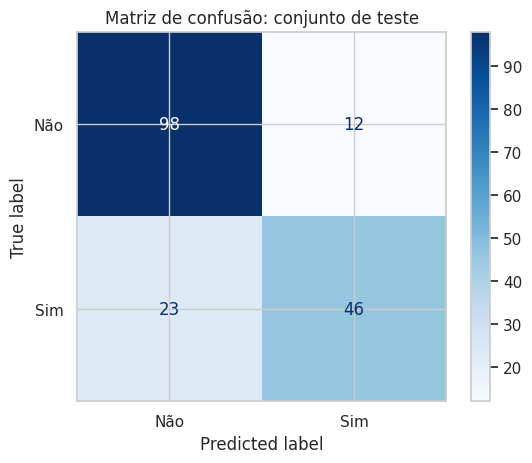

In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, ConfusionMatrixDisplay

y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:,1]
resultados = pd.Series({
    "Acurácia":accuracy_score(y_test,y_pred),
    "Precisão":precision_score(y_test,y_pred,zero_division=0),
    "Recall":recall_score(y_test,y_pred,zero_division=0),
    "F1":f1_score(y_test,y_pred,zero_division=0),
    "ROC AUC":roc_auc_score(y_test,y_prob)
})
display(resultados.to_frame("Resultado no teste").style.format({"Resultado no teste":"{:.3f}"}))
print(classification_report(y_test,y_pred,target_names=["Não sobreviveu","Sobreviveu"]))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,display_labels=["Não","Sim"],cmap="Blues")
plt.title("Matriz de confusão: conjunto de teste")
plt.show()

### 8.1. Comparação com um modelo ingênuo

Um classificador que prevê sempre a classe majoritária pode alcançar acurácia razoável sem aprender padrões relevantes. Por isso, compare o desempenho com essa referência.

In [23]:
from sklearn.dummy import DummyClassifier
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train,y_train)
print(f"Acurácia do modelo ingênuo: {baseline.score(X_test,y_test):.3f}")
print(f"Acurácia da regressão logística: {accuracy_score(y_test,y_pred):.3f}")

Acurácia do modelo ingênuo: 0.615
Acurácia da regressão logística: 0.804


## 9. Validação cruzada (opcional)

O teste final deve continuar separado. A validação cruzada aqui é feita **somente dentro do conjunto de treinamento** e a pipeline é reajustada em cada divisão. Essa etapa ilustra a variabilidade de desempenho entre partições.

In [24]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
pontuacoes = cross_val_score(modelo,X_train,y_train,cv=cv,scoring="accuracy")
print("Acurácia por divisão:",np.round(pontuacoes,3))
print(f"Média: {pontuacoes.mean():.3f}; desvio padrão: {pontuacoes.std():.3f}")

Acurácia por divisão: [0.797 0.797 0.81  0.746 0.831]
Média: 0.796; desvio padrão: 0.028


## 10. Testar uma observação hipotética

Os valores abaixo são **fictícios**, apenas para demonstrar o formato das entradas. A probabilidade estimada não é uma certeza sobre uma pessoa.

In [25]:
novo = pd.DataFrame([{
    "Pclass":3, "Sex":"female", "Age":28,
    "SibSp":0,"Parch":0,"Fare":15.0,"Embarked":"S"
}])
print("Classe estimada:",int(modelo.predict(novo)[0]))
print("Probabilidade estimada de sobrevivência:",round(float(modelo.predict_proba(novo)[0,1]),3))

Classe estimada: 1
Probabilidade estimada de sobrevivência: 0.579
